# Dendritic ANN nonlinearities on CIFAR-10 (Colab)

Runs control 1 (homogeneous type) and the per-dendrite ratio sweep on CIFAR-10 with a GPU.
The dataset is downloaded to this Colab machine only; nothing lands on your laptop except the
small results zip at the end.

**Before running:** Runtime > Change runtime type > GPU (a T4 is fine). Then run the cells top to bottom.
Free Colab sessions can time out; the sweep skips finished runs, so just re-run the cells. Mounting
Google Drive (optional cell below) keeps the results across sessions.

In [1]:
!nvidia-smi -L
import torch
print("cuda available:", torch.cuda.is_available())

GPU 0: Tesla T4 (UUID: GPU-19baec85-07b0-85af-9ed7-a0967aca0b5c)
cuda available: True


## 1. Get the code
Clones the `v1-nonlinearities` branch. Re-running this cell is safe.

In [2]:
%cd /content
![ -d NEU231_Final_Project ] || git clone -b v1-nonlinearities https://github.com/HillaryKchao/NEU231_Final_Project.git
%cd /content/NEU231_Final_Project
!git pull -q
!pip install -q -r requirements.txt

/content
Cloning into 'NEU231_Final_Project'...
remote: Enumerating objects: 90, done.
remote: Counting objects: 100% (90/90), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 90 (delta 32), reused 76 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (90/90), 3.24 MiB | 8.12 MiB/s, done.
Resolving deltas: 100% (32/32), done.
/content/NEU231_Final_Project


## 2. Where to keep results
Set `USE_DRIVE = True` to store results in your Google Drive (survives a session timeout).
Otherwise they stay on this machine until you download the zip at the end.

In [4]:
import os
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/neu231/results"
else:
    OUT = "/content/NEU231_Final_Project/results"
os.makedirs(OUT, exist_ok=True)
os.environ["OUT"] = OUT          # the shell cells below read $OUT
os.environ["DATASET"] = "cifar10"
print("results go to", OUT)

Mounted at /content/drive
results go to /content/drive/MyDrive/neu231/results


## 3. Smoke test (about a minute)
One epoch on 5,000 training images. Downloads CIFAR-10 to this machine's `data/` folder.
Expect `cuda` in the first line and a test accuracy around 30-35%.

In [5]:
!python base_model.py --dataset cifar10 --dends 16 --soma 256 --epochs 1 --train-subset 5000 --out /tmp/smoke

100% 170M/170M [08:34<00:00, 332kB/s]
dANN-local | leaky dendrites | cifar10 | 1 layer(s) | 16 dends x 256 somata | 207,626 trainable params | cuda
images: train 5,000 | val 5,000 | test 10,000  (TRAIN SUBSET)
epoch   1/1  train loss 2.2809 acc 0.1590 | val loss 2.2413 acc 0.1978 | 0.9s

Test acc: 0.2003 | Test loss: 2.2409
Saved /tmp/smoke/dann_local_cifar10_L1_d16_s256_seed1_n5000.json and .pt


## 4. Control 1 on CIFAR-10
LeakyReLU baseline, supra-only, sub-only, Ca-only and V1 mixed; seeds 1-3 at 16 x 256, 50 epochs each.
Roughly 2 hours on a T4. Already-finished runs are skipped, so re-run after a timeout.

In [6]:
!DATASET=cifar10 OUT=$OUT bash sweep_controls.sh

=== seed 1 | 16 dends x 256 somata | leaky  ===
dANN-local | leaky dendrites | cifar10 | 1 layer(s) | 16 dends x 256 somata | 207,626 trainable params | cuda
images: train 45,000 | val 5,000 | test 10,000
epoch   1/50  train loss 1.9712 acc 0.2935 | val loss 1.8153 acc 0.3742 | 3.0s
epoch   2/50  train loss 1.7442 acc 0.3874 | val loss 1.6776 acc 0.4166 | 2.8s
epoch   3/50  train loss 1.6369 acc 0.4266 | val loss 1.5965 acc 0.4472 | 2.8s
epoch   4/50  train loss 1.5546 acc 0.4521 | val loss 1.5492 acc 0.4636 | 2.8s
epoch   5/50  train loss 1.4933 acc 0.4733 | val loss 1.4805 acc 0.4776 | 2.8s
epoch   6/50  train loss 1.4469 acc 0.4876 | val loss 1.4475 acc 0.4884 | 2.8s
epoch   7/50  train loss 1.4052 acc 0.5002 | val loss 1.4249 acc 0.4934 | 2.8s
epoch   8/50  train loss 1.3754 acc 0.5135 | val loss 1.3956 acc 0.4992 | 2.8s
epoch   9/50  train loss 1.3441 acc 0.5250 | val loss 1.3848 acc 0.5052 | 2.8s
epoch  10/50  train loss 1.3205 acc 0.5300 | val loss 1.3528 acc 0.5156 | 2.8s
epoch

## 5. Ratio sweep on CIFAR-10
One nonlinearity per dendrite at 12:3:1 (biological), 1:1:1 and 1:3:12; seeds 1-3. About an hour.

In [7]:
!DATASET=cifar10 NONLINS=branch OUT=$OUT bash sweep_controls.sh

=== seed 1 | 16 dends x 256 somata | branch 12:3:1 ===
dANN-local | branch dendrites | cifar10 | 1 layer(s) | 16 dends x 256 somata | 207,626 trainable params | cuda
images: train 45,000 | val 5,000 | test 10,000
epoch   1/50  train loss 1.9561 acc 0.3037 | val loss 1.7973 acc 0.3724 | 3.3s
epoch   2/50  train loss 1.7133 acc 0.4009 | val loss 1.6684 acc 0.4082 | 3.0s
epoch   3/50  train loss 1.6136 acc 0.4350 | val loss 1.5927 acc 0.4382 | 3.0s
epoch   4/50  train loss 1.5486 acc 0.4542 | val loss 1.5672 acc 0.4488 | 3.0s
epoch   5/50  train loss 1.5005 acc 0.4688 | val loss 1.5197 acc 0.4596 | 3.0s
epoch   6/50  train loss 1.4615 acc 0.4819 | val loss 1.4872 acc 0.4714 | 3.0s
epoch   7/50  train loss 1.4257 acc 0.4950 | val loss 1.4632 acc 0.4716 | 3.0s
epoch   8/50  train loss 1.4013 acc 0.5032 | val loss 1.4418 acc 0.4822 | 3.0s
epoch   9/50  train loss 1.3745 acc 0.5132 | val loss 1.4389 acc 0.4812 | 3.0s
epoch  10/50  train loss 1.3525 acc 0.5215 | val loss 1.4075 acc 0.4936 | 3.

## 6. Figures and tables
Writes figures 1-8 and the CSVs for CIFAR-10 into `figures/cifar10/`, then inspects the V1 mixed model.

In [8]:
!python plot_results.py --results $OUT --dataset cifar10 --out figures/cifar10
!python analyze_v1.py $OUT/dann_v1_local_cifar10_L1_d16_s256_seed1 --data-dir data --out figures/cifar10

Loaded 24 runs = 8 model configurations
  wrote figures/cifar10/1_paper_comparison.png
  wrote figures/cifar10/2_size_sweep.png
  skipping 3_dendrites_per_soma.png: need >= 2 dendrite counts at one soma count
  wrote figures/cifar10/4_learning_curves.png
  wrote figures/cifar10/7_control_homogeneous.png
  wrote figures/cifar10/8_ratio_sweep.png
  wrote figures/cifar10/summary.csv

Best model vs paper Table 1 (test accuracy, %)
dataset   model                    best size              seeds           yours           paper    diff  verdict
cifar10   dANN-LRF                 16 dends x 256 somata      3  57.43 +/- 0.93  56.97 +/- 0.98   +0.46  matches paper
cifar10   dANN-LRF supra-only      16 dends x 256 somata      3  56.23 +/- 0.17  56.97 +/- 0.98   -0.74  matches paper
cifar10   dANN-LRF sub-only        16 dends x 256 somata      3  55.89 +/- 0.83  56.97 +/- 0.98   -1.07  matches paper
cifar10   dANN-LRF Ca-only         16 dends x 256 somata      3  55.50 +/- 0.23  56.97 +/- 0.98   -

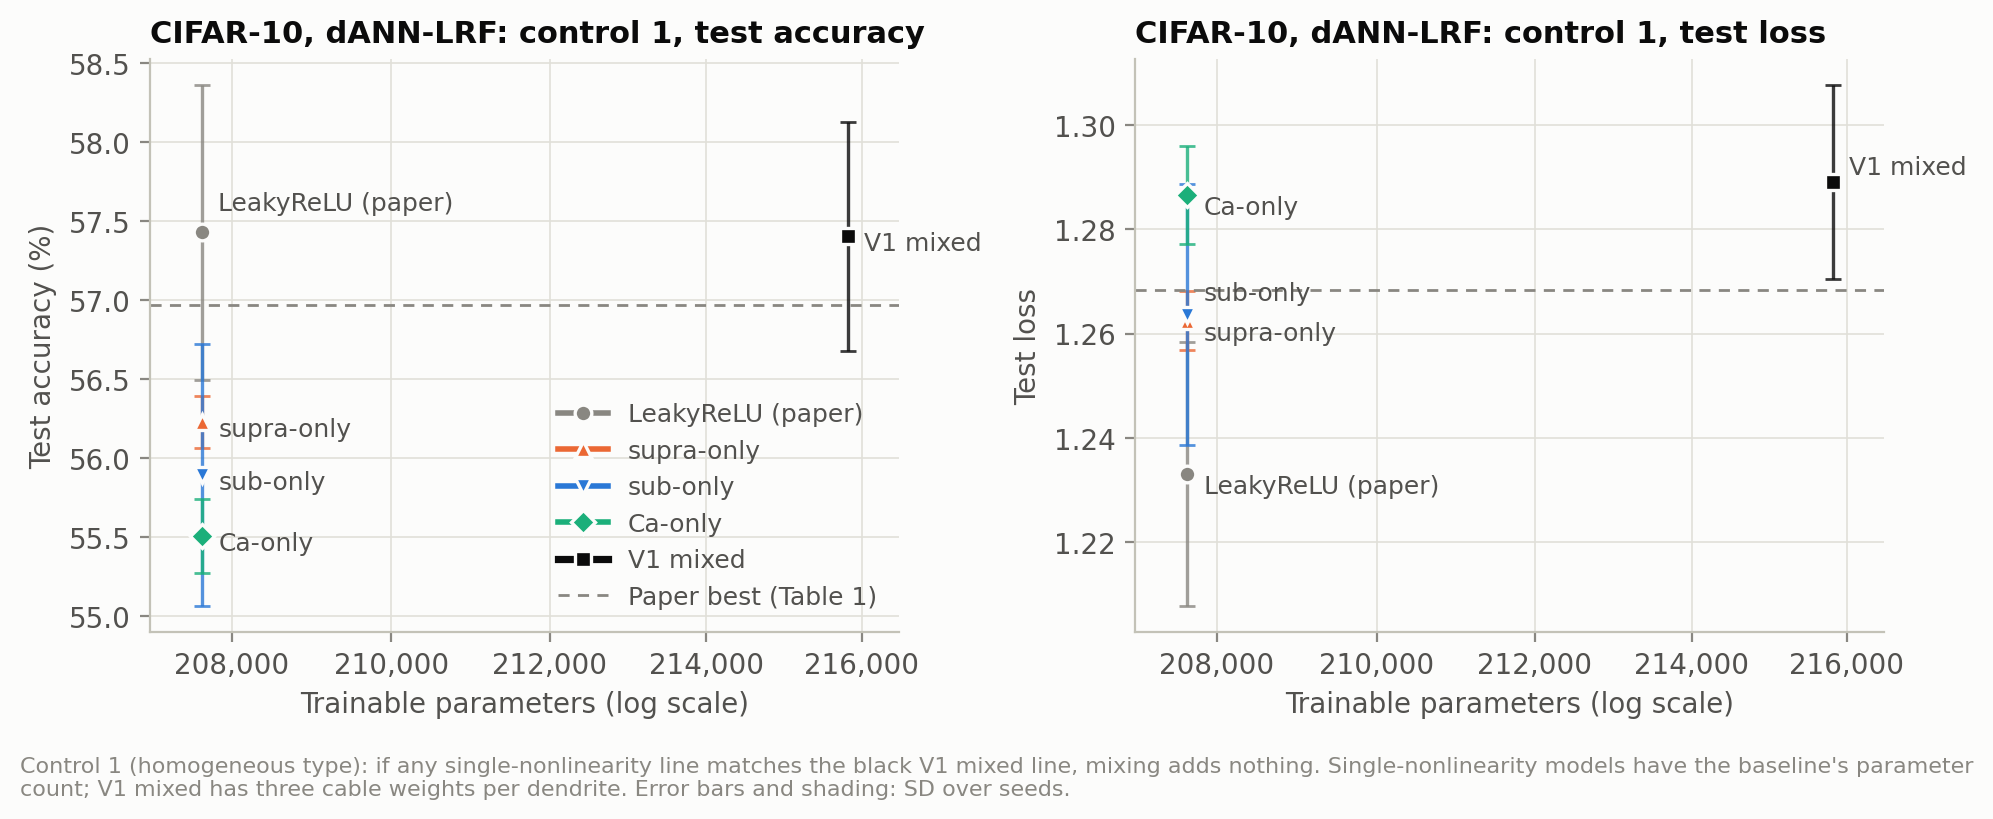

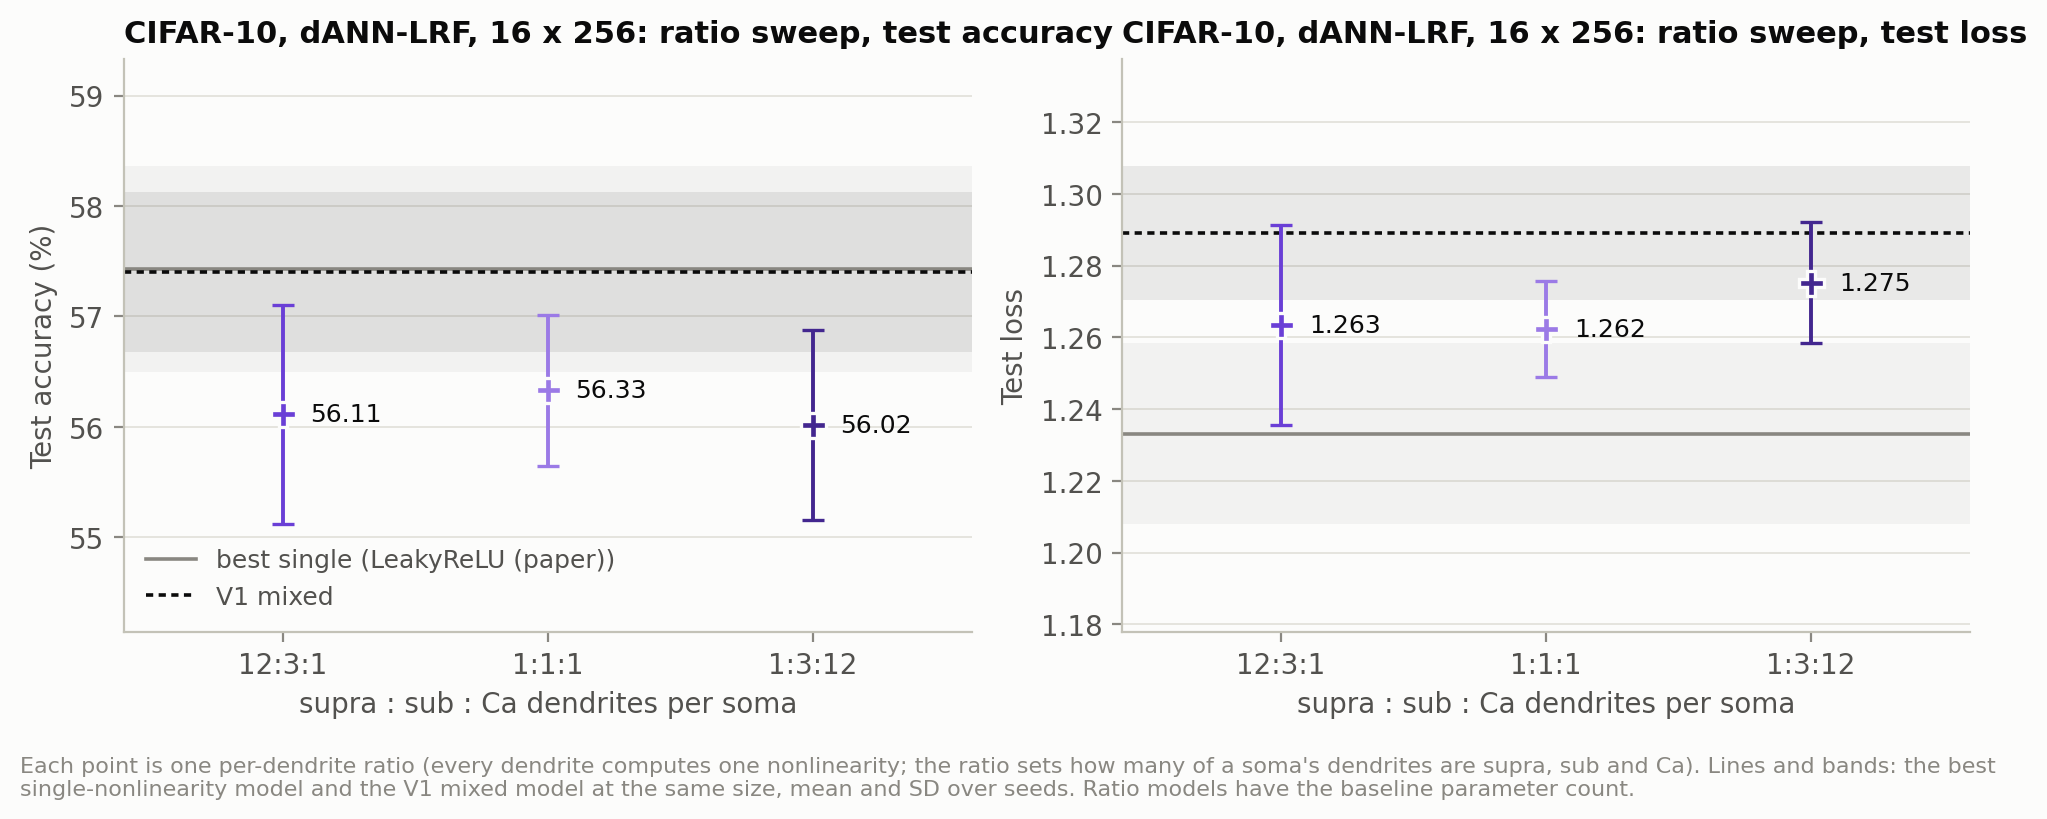

In [9]:
from IPython.display import Image, display
for f in ["7_control_homogeneous.png", "8_ratio_sweep.png"]:
    display(Image(f"figures/cifar10/{f}"))

## 7. Bring the results home
Zips the result JSONs (the numbers), the CIFAR-10 figures and the log, and downloads it.
The `.pt` weight files are left out (about 1 MB each); set `INCLUDE_WEIGHTS = True` if you want them.
Locally, unzip into the repo and run `python plot_results.py --results results --dataset cifar10 --out figures/cifar10`
to regenerate the figures from the JSONs.

In [1]:
INCLUDE_WEIGHTS = False
pattern = "$OUT/*cifar10*" if INCLUDE_WEIGHTS else "$OUT/*cifar10*.json"
!rm -f /content/results_cifar10.zip
!zip -q -j /content/results_cifar10.zip {pattern} sweep_controls.log
!zip -q -r /content/results_cifar10.zip figures/cifar10
!ls -lh /content/results_cifar10.zip
from google.colab import files
files.download("/content/results_cifar10.zip")


zip error: Nothing to do! (/content/results_cifar10.zip)

zip error: Nothing to do! (try: zip -q -r /content/results_cifar10.zip . -i figures/cifar10)
ls: cannot access '/content/results_cifar10.zip': No such file or directory


FileNotFoundError: Cannot find file: /content/results_cifar10.zip